# 🎯 XGBoost Insulin Dosage Prediction

**Model:** XGBoost Regressor (GPU Accelerated)  
**Target:** `bolus` (Insulin dosage prediction)  
**Dataset:** ~10.6M rows, balanced (25% positive)

---

## 🔗 1. Google Drive'a Bağlan

In [1]:
from google.colab import drive
drive.mount('/content/drive')

print("✅ Google Drive bağlandı!")

Mounted at /content/drive
✅ Google Drive bağlandı!


## 📦 2. Kütüphaneleri Kur ve İçe Aktar

In [2]:
!pip install polars xgboost -q

In [3]:
import polars as pl
import numpy as np
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import time
import os

print(f"✅ Polars: {pl.__version__}")
print(f"✅ XGBoost: {xgb.__version__}")

✅ Polars: 1.31.0
✅ XGBoost: 3.1.3


In [4]:
# GPU kontrolü - ZORUNLU!
import subprocess

try:
    result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    print("✅ GPU BULUNDU:")
    print(result.stdout.split('\n')[8])  # GPU adını göster
except:
    raise RuntimeError("❌ GPU BULUNAMADI! Runtime → Change runtime type → GPU seçin!")

✅ GPU BULUNDU:
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |


## 📂 3. Konfigürasyon

In [5]:
# ==============================================================================
# KONFİGÜRASYON
# ==============================================================================

BASE_PATH = "/content/drive/MyDrive/DiabetesKDS/data/processed"

# Dosyalar
INPUT_FILE = f"{BASE_PATH}/train_augmented_fixed.parquet"
MODEL_OUTPUT = f"{BASE_PATH}/xgboost_insulin_model.json"

# ✅ YENİ ÖZELLİK LİSTESİ (Modelin Zekasını Artıracak Eklemeler)
FEATURES = [
    # 1. Eski Özellikler (Zaman Serisi & Anlık Durum)
    'CGM',
    'carbs',
    'time_sin',
    'time_cos',
    'is_weekend',
    'cgm_delta_5min',
    'cgm_delta_15min',

    # 2. YENİ EKLENEN HASTA PROFİLİ (Metadata)
    'basal',                # Hastanın arka plan insülin direnci (Çok Önemli!)
    'age',                  # Yaş
    'weight',               # Kilo (İnsülin duyarlılığı için kritik)
    'gender_encoded',       # Cinsiyet (0 veya 1)
    'insulin_type_encoded'  # Kullanılan insülinin markası/türü
]

TARGET = 'bolus'

# Training parametreleri
TEST_SIZE = 0.20
RANDOM_SEED = 42
SCALE_POS_WEIGHT = 50.0  # 1:3 dengesizlik için

print("=" * 70)
print("🎯 XGBoost Insulin Dosage Prediction")
print("=" * 70)
print(f"\n📂 Input: {INPUT_FILE}")
print(f"📂 Model Output: {MODEL_OUTPUT}")
print(f"\n📊 Features: {FEATURES}")
print(f"🎯 Target: {TARGET}")

🎯 XGBoost Insulin Dosage Prediction

📂 Input: /content/drive/MyDrive/DiabetesKDS/data/processed/train_augmented_fixed.parquet
📂 Model Output: /content/drive/MyDrive/DiabetesKDS/data/processed/xgboost_insulin_model.json

📊 Features: ['CGM', 'carbs', 'time_sin', 'time_cos', 'is_weekend', 'cgm_delta_5min', 'cgm_delta_15min', 'basal', 'age', 'weight', 'gender_encoded', 'insulin_type_encoded']
🎯 Target: bolus


## 📖 4. Veriyi Yükle (Polars - Hızlı!)

In [6]:
print("-" * 70)
print("📖 Veri yükleniyor (Polars)...")
print("-" * 70)

start_time = time.time()

# Polars ile hızlı yükleme
df = pl.read_parquet(INPUT_FILE)

load_time = time.time() - start_time

print(f"✅ Veri yüklendi: {len(df):,} satır × {len(df.columns)} sütun")
print(f"⏱️  Yükleme süresi: {load_time:.2f} saniye")
print(f"\n📊 Sütunlar: {df.columns}")

----------------------------------------------------------------------
📖 Veri yükleniyor (Polars)...
----------------------------------------------------------------------
✅ Veri yüklendi: 11,373,548 satır × 19 sütun
⏱️  Yükleme süresi: 36.59 saniye

📊 Sütunlar: ['id', 'date', 'source_file', 'CGM', 'bolus', 'carbs', 'time_sin', 'time_cos', 'day_of_week', 'is_weekend', 'cgm_delta_5min', 'cgm_delta_15min', 'basal', 'age', 'weight', 'gender', 'insulin_type_bolus', 'gender_encoded', 'insulin_type_encoded']


In [7]:
# Veri özeti
n_positive = df.filter(pl.col(TARGET) > 0).height
n_negative = df.filter(pl.col(TARGET) == 0).height
balance_ratio = n_negative / n_positive if n_positive > 0 else 0

print(f"\n📊 Sınıf Dağılımı:")
print(f"   Pozitif (bolus > 0): {n_positive:,} ({n_positive/len(df)*100:.1f}%)")
print(f"   Negatif (bolus = 0): {n_negative:,} ({n_negative/len(df)*100:.1f}%)")
print(f"   Oran: 1:{balance_ratio:.1f}")


📊 Sınıf Dağılımı:
   Pozitif (bolus > 0): 2,824,720 (24.8%)
   Negatif (bolus = 0): 8,548,828 (75.2%)
   Oran: 1:3.0


## 🔀 5. Train/Test Split

In [8]:
print("-" * 70)
print("🔀 Train/Test split yapılıyor...")
print("-" * 70)

# Feature ve Target ayır
X = df.select(FEATURES).to_numpy()
y = df.select(TARGET).to_numpy().ravel()

print(f"📊 X shape: {X.shape}")
print(f"📊 y shape: {y.shape}")

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    shuffle=True,
    random_state=RANDOM_SEED
)

print(f"\n✅ Train set: {X_train.shape[0]:,} satır")
print(f"✅ Test set:  {X_test.shape[0]:,} satır")

# Bellek temizle
del df, X, y
import gc
gc.collect()

----------------------------------------------------------------------
🔀 Train/Test split yapılıyor...
----------------------------------------------------------------------
📊 X shape: (11373548, 12)
📊 y shape: (11373548,)

✅ Train set: 9,098,838 satır
✅ Test set:  2,274,710 satır


0

## 🚀 6. XGBoost DMatrix Oluştur (GPU)

In [9]:
print("-" * 70)
print("🚀 XGBoost DMatrix oluşturuluyor (GPU)...")
print("-" * 70)

# DMatrix oluştur - GPU için optimize
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=FEATURES)
dtest = xgb.DMatrix(X_test, label=y_test, feature_names=FEATURES)

print(f"✅ DMatrix oluşturuldu")
print(f"   Train: {dtrain.num_row():,} rows")
print(f"   Test:  {dtest.num_row():,} rows")

----------------------------------------------------------------------
🚀 XGBoost DMatrix oluşturuluyor (GPU)...
----------------------------------------------------------------------
✅ DMatrix oluşturuldu
   Train: 9,098,838 rows
   Test:  2,274,710 rows


## ⚙️ 7. XGBoost Parametreleri

In [10]:
# ==============================================================================
# XGBOOST PARAMETRELERİ - GPU ACCELERATED
# ==============================================================================

params = {
    # Objective
    'objective': 'reg:squarederror',
    'eval_metric': ['rmse', 'mae'],

    # GPU Acceleration - ZORUNLU!
    'device': 'cuda',
    'tree_method': 'hist',  # GPU hist for speed

    # Model complexity
    'max_depth': 12,
    'min_child_weight': 1,
    'gamma': 0.1,

    # Learning
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,

    # Regularization
    'reg_alpha': 0.1,   # L1
    'reg_lambda': 1.0,  # L2

    # İmbalance handling
    'scale_pos_weight': SCALE_POS_WEIGHT,

    # Reproducibility
    'seed': RANDOM_SEED,
}

NUM_ROUNDS = 500
EARLY_STOPPING = 50

print("⚙️ XGBoost Parametreleri:")
for k, v in params.items():
    print(f"   {k}: {v}")
print(f"\n📊 Rounds: {NUM_ROUNDS}, Early Stopping: {EARLY_STOPPING}")

⚙️ XGBoost Parametreleri:
   objective: reg:squarederror
   eval_metric: ['rmse', 'mae']
   device: cuda
   tree_method: hist
   max_depth: 12
   min_child_weight: 1
   gamma: 0.1
   learning_rate: 0.1
   subsample: 0.8
   colsample_bytree: 0.8
   reg_alpha: 0.1
   reg_lambda: 1.0
   scale_pos_weight: 50.0
   seed: 42

📊 Rounds: 500, Early Stopping: 50


## 🏋️ 8. Model Eğitimi

In [11]:
print("=" * 70)
print("🏋️ XGBoost EĞİTİMİ BAŞLIYOR (GPU)")
print("=" * 70)

train_start = time.time()

# Eğitim
evals = [(dtrain, 'train'), (dtest, 'test')]

model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=NUM_ROUNDS,
    evals=evals,
    early_stopping_rounds=EARLY_STOPPING,
    verbose_eval=50  # Her 50 round'da bir göster
)

train_time = time.time() - train_start

print("\n" + "=" * 70)
print(f"✅ EĞİTİM TAMAMLANDI!")
print(f"⏱️  Eğitim süresi: {train_time:.2f} saniye ({train_time/60:.1f} dakika)")
print(f"🌳 Best iteration: {model.best_iteration}")
print(f"📊 Best score: {model.best_score:.6f}")

🏋️ XGBoost EĞİTİMİ BAŞLIYOR (GPU)
[0]	train-rmse:1.38190	train-mae:0.81828	test-rmse:1.37994	test-mae:0.81853
[50]	train-rmse:0.94274	train-mae:0.48564	test-rmse:0.96127	test-mae:0.49161
[100]	train-rmse:0.91013	train-mae:0.45772	test-rmse:0.94234	test-mae:0.46768
[150]	train-rmse:0.89201	train-mae:0.44298	test-rmse:0.93525	test-mae:0.45636
[200]	train-rmse:0.87806	train-mae:0.43272	test-rmse:0.93088	test-mae:0.44909
[250]	train-rmse:0.86565	train-mae:0.42472	test-rmse:0.92820	test-mae:0.44421
[300]	train-rmse:0.85548	train-mae:0.41796	test-rmse:0.92612	test-mae:0.44024
[350]	train-rmse:0.84466	train-mae:0.41148	test-rmse:0.92460	test-mae:0.43675
[400]	train-rmse:0.83495	train-mae:0.40526	test-rmse:0.92332	test-mae:0.43343
[450]	train-rmse:0.82513	train-mae:0.39955	test-rmse:0.92239	test-mae:0.43062
[499]	train-rmse:0.81602	train-mae:0.39405	test-rmse:0.92149	test-mae:0.42789

✅ EĞİTİM TAMAMLANDI!
⏱️  Eğitim süresi: 50.21 saniye (0.8 dakika)
🌳 Best iteration: 499
📊 Best score: 0.427890

## 📊 9. Model Değerlendirmesi

In [12]:
print("=" * 70)
print("📊 MODEL DEĞERLENDİRMESİ")
print("=" * 70)

# Tahminler
y_pred = model.predict(dtest)

# Negatif tahminleri sıfırla (insulin negatif olamaz)
y_pred = np.maximum(y_pred, 0)

print(f"\n📊 Tahmin istatistikleri:")
print(f"   Min: {y_pred.min():.4f}")
print(f"   Max: {y_pred.max():.4f}")
print(f"   Mean: {y_pred.mean():.4f}")
print(f"   Std: {y_pred.std():.4f}")

📊 MODEL DEĞERLENDİRMESİ

📊 Tahmin istatistikleri:
   Min: 0.0000
   Max: 30.0393
   Mean: 0.5330
   Std: 1.0718


In [13]:
# ==============================================================================
# METRIC 1: GLOBAL RMSE & MAE (Tüm veriler)
# ==============================================================================

global_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
global_mae = mean_absolute_error(y_test, y_pred)

print("-" * 70)
print("📈 METRIC 1: Global Performans (Tüm Test Seti)")
print("-" * 70)
print(f"   RMSE: {global_rmse:.4f}")
print(f"   MAE:  {global_mae:.4f}")
print(f"   Test samples: {len(y_test):,}")

----------------------------------------------------------------------
📈 METRIC 1: Global Performans (Tüm Test Seti)
----------------------------------------------------------------------
   RMSE: 0.9210
   MAE:  0.4216
   Test samples: 2,274,710


In [14]:
# ==============================================================================
# METRIC 2: POSITIVE-ONLY MAE (⭐ EN ÖNEMLİ METRİK!)
# ==============================================================================

# Sadece gerçek bolus > 0 olan satırları filtrele
positive_mask = y_test > 0
y_test_positive = y_test[positive_mask]
y_pred_positive = y_pred[positive_mask]

positive_mae = mean_absolute_error(y_test_positive, y_pred_positive)
positive_rmse = np.sqrt(mean_squared_error(y_test_positive, y_pred_positive))

print("-" * 70)
print("⭐ METRIC 2: Positive-Only Performans (Bolus > 0)")
print("-" * 70)
print(f"   RMSE: {positive_rmse:.4f}")
print(f"   MAE:  {positive_mae:.4f}  ← EN ÖNEMLİ!")
print(f"   Positive samples: {len(y_test_positive):,}")
print(f"   Ortalama gerçek bolus: {y_test_positive.mean():.4f}")
print(f"   Ortalama tahmin: {y_pred_positive.mean():.4f}")

----------------------------------------------------------------------
⭐ METRIC 2: Positive-Only Performans (Bolus > 0)
----------------------------------------------------------------------
   RMSE: 1.6838
   MAE:  0.8333  ← EN ÖNEMLİ!
   Positive samples: 565,440
   Ortalama gerçek bolus: 1.7654
   Ortalama tahmin: 1.2814


In [15]:
# ==============================================================================
# ÖZET RAPOR
# ==============================================================================

print("\n" + "=" * 70)
print("📋 ÖZET PERFORMANS RAPORU")
print("=" * 70)

print(f"""
┌─────────────────────────────────────────────────────────────────────┐
│  GLOBAL METRİKLER (Tüm Test Seti: {len(y_test):,} satır)                  │
├─────────────────────────────────────────────────────────────────────┤
│  RMSE:                              {global_rmse:>12.4f}                   │
│  MAE:                               {global_mae:>12.4f}                   │
└─────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────┐
│  ⭐ POZİTİF-ONLY METRİKLER (bolus > 0: {len(y_test_positive):,} satır)            │
├─────────────────────────────────────────────────────────────────────┤
│  RMSE:                              {positive_rmse:>12.4f}                   │
│  MAE:                               {positive_mae:>12.4f}  ← KEY METRIC    │
└─────────────────────────────────────────────────────────────────────┘

🏋️ Eğitim Süresi: {train_time:.1f} saniye
🌳 Best Iteration: {model.best_iteration}
""")


📋 ÖZET PERFORMANS RAPORU

┌─────────────────────────────────────────────────────────────────────┐
│  GLOBAL METRİKLER (Tüm Test Seti: 2,274,710 satır)                  │
├─────────────────────────────────────────────────────────────────────┤
│  RMSE:                                    0.9210                   │
│  MAE:                                     0.4216                   │
└─────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────┐
│  ⭐ POZİTİF-ONLY METRİKLER (bolus > 0: 565,440 satır)            │
├─────────────────────────────────────────────────────────────────────┤
│  RMSE:                                    1.6838                   │
│  MAE:                                     0.8333  ← KEY METRIC    │
└─────────────────────────────────────────────────────────────────────┘

🏋️ Eğitim Süresi: 50.2 saniye
🌳 Best Iteration: 499



## 📊 10. Feature Importance

In [16]:
print("-" * 70)
print("📊 Feature Importance")
print("-" * 70)

importance = model.get_score(importance_type='gain')
importance_sorted = sorted(importance.items(), key=lambda x: x[1], reverse=True)

print("\n🏆 Feature Ranking (Gain):")
for i, (feat, score) in enumerate(importance_sorted, 1):
    bar = '█' * int(score / max(importance.values()) * 30)
    print(f"   {i}. {feat:20s} {score:>10.2f} {bar}")

----------------------------------------------------------------------
📊 Feature Importance
----------------------------------------------------------------------

🏆 Feature Ranking (Gain):
   1. carbs                    289.38 ██████████████████████████████
   2. weight                    62.42 ██████
   3. age                       50.23 █████
   4. gender_encoded            42.16 ████
   5. insulin_type_encoded      40.00 ████
   6. basal                     38.89 ████
   7. CGM                       22.43 ██
   8. cgm_delta_15min           21.88 ██
   9. time_sin                  16.37 █
   10. cgm_delta_5min            16.14 █
   11. time_cos                  15.97 █
   12. is_weekend                10.76 █


## 💾 11. Modeli Kaydet

In [17]:
print("-" * 70)
print("💾 Model kaydediliyor...")
print("-" * 70)

# JSON formatında kaydet
model.save_model(MODEL_OUTPUT)

# Dosya boyutunu kontrol et
model_size_mb = os.path.getsize(MODEL_OUTPUT) / (1024**2)

print(f"✅ Model kaydedildi: {MODEL_OUTPUT}")
print(f"📦 Dosya boyutu: {model_size_mb:.2f} MB")

----------------------------------------------------------------------
💾 Model kaydediliyor...
----------------------------------------------------------------------
✅ Model kaydedildi: /content/drive/MyDrive/DiabetesKDS/data/processed/xgboost_insulin_model.json
📦 Dosya boyutu: 124.00 MB


## ✅ 12. Tamamlandı!

In [18]:
print("\n" + "=" * 70)
print("🎉 XGBoost EĞİTİMİ BAŞARIYLA TAMAMLANDI!")
print("=" * 70)

print(f"""
📂 Kaydedilen dosya: {MODEL_OUTPUT}

📊 Sonuçlar:
   • Global MAE: {global_mae:.4f}
   • Positive-Only MAE: {positive_mae:.4f}

🚀 Modeli yüklemek için:

```python
import xgboost as xgb

model = xgb.Booster()
model.load_model("{MODEL_OUTPUT}")

# Tahmin
dmatrix = xgb.DMatrix(features)
predictions = model.predict(dmatrix)
```
""")


🎉 XGBoost EĞİTİMİ BAŞARIYLA TAMAMLANDI!

📂 Kaydedilen dosya: /content/drive/MyDrive/DiabetesKDS/data/processed/xgboost_insulin_model.json

📊 Sonuçlar:
   • Global MAE: 0.4216
   • Positive-Only MAE: 0.8333

🚀 Modeli yüklemek için:

```python
import xgboost as xgb

model = xgb.Booster()
model.load_model("/content/drive/MyDrive/DiabetesKDS/data/processed/xgboost_insulin_model.json")

# Tahmin
dmatrix = xgb.DMatrix(features)
predictions = model.predict(dmatrix)
```



---

## 🔬 Bonus: Örnek Tahminler

In [19]:
# Pozitif örneklerden rastgele 10 tanesini göster
print("\n🔬 Örnek Tahminler (Pozitif Vakalar):")
print("-" * 50)

np.random.seed(42)
sample_indices = np.random.choice(np.where(positive_mask)[0], size=min(10, sum(positive_mask)), replace=False)

print(f"{'Index':>8} | {'Gerçek':>10} | {'Tahmin':>10} | {'Hata':>10}")
print("-" * 50)

for idx in sample_indices:
    actual = y_test[idx]
    pred = y_pred[idx]
    error = abs(actual - pred)
    print(f"{idx:>8} | {actual:>10.4f} | {pred:>10.4f} | {error:>10.4f}")


🔬 Örnek Tahminler (Pozitif Vakalar):
--------------------------------------------------
   Index |     Gerçek |     Tahmin |       Hata
--------------------------------------------------
  662848 |     0.2500 |     0.3455 |     0.0955
 2136362 |     0.0583 |     0.2690 |     0.2106
  285321 |     0.2501 |     0.1095 |     0.1406
   25034 |     2.0000 |     0.7813 |     1.2187
  438927 |     0.5000 |     0.2279 |     0.2721
 2028811 |     8.0000 |     5.9478 |     2.0522
  415579 |     0.9000 |     0.4906 |     0.4094
 1628456 |     2.3000 |     0.4996 |     1.8004
 1108465 |     0.0917 |     0.2696 |     0.1779
  599567 |     4.0000 |     3.2440 |     0.7560


🩺 KLİNİK GÜVENLİK ANALİZİ
⚠️ Kritik 'Atlanan Doz' Analizi:
   Toplam İnsülin Gereken Durum: 565,440
   Modelin 'İnsülin Yok' Dediği: 62,255
   Hata Oranı (False Negative):  %11.01
   ❌ UYARI: Model doz atlama eğiliminde! 'scale_pos_weight' artırılabilir.


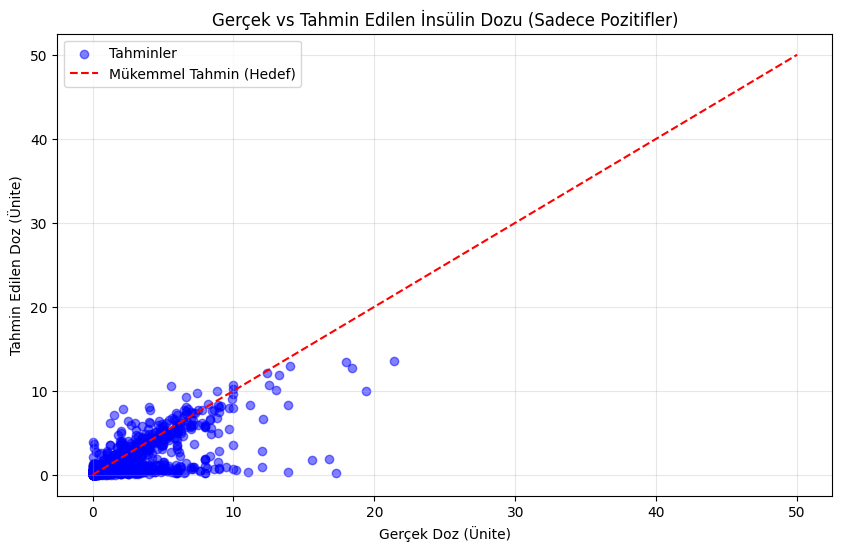

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("🩺 KLİNİK GÜVENLİK ANALİZİ")
print("=" * 70)

# 1. FALSE NEGATIVE KONTROLÜ (Tehlikeli Durum)
# Gerçekte insülin var (>0.5 ünite) ama model yok dedi (<0.5 ünite)
# Not: 0.5 ünite genelde insülin kalemlerinin minimum dozudur.
threshold = 0.5
missed_doses = np.sum((y_test_positive > threshold) & (y_pred_positive < threshold))
total_doses = len(y_test_positive)
miss_rate = (missed_doses / total_doses) * 100

print(f"⚠️ Kritik 'Atlanan Doz' Analizi:")
print(f"   Toplam İnsülin Gereken Durum: {total_doses:,}")
print(f"   Modelin 'İnsülin Yok' Dediği: {missed_doses:,}")
print(f"   Hata Oranı (False Negative):  %{miss_rate:.2f}")

if miss_rate > 5:
    print("   ❌ UYARI: Model doz atlama eğiliminde! 'scale_pos_weight' artırılabilir.")
else:
    print("   ✅ GÜVENLİ: Doz atlama oranı düşük.")

# 2. GÖRSELLEŞTİRME (Scatter Plot)
# Veri çok büyük olduğu için rastgele 2000 nokta seçip çizelim
plt.figure(figsize=(10, 6))
indices = np.random.choice(len(y_test_positive), size=min(2000, len(y_test_positive)), replace=False)

plt.scatter(y_test_positive[indices], y_pred_positive[indices], alpha=0.5, color='blue', label='Tahminler')
plt.plot([0, y_test_positive.max()], [0, y_test_positive.max()], 'r--', label='Mükemmel Tahmin (Hedef)')

plt.title('Gerçek vs Tahmin Edilen İnsülin Dozu (Sadece Pozitifler)')
plt.xlabel('Gerçek Doz (Ünite)')
plt.ylabel('Tahmin Edilen Doz (Ünite)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [21]:
import numpy as np

print("=" * 70)
print("🛡️ AKILLI GÜVENLİK AĞI (V2.0) DEVREDE")
print("=" * 70)

# 1. Ham tahminleri al
safety_predictions = model.predict(dtest).copy()

# X_test verisinden CGM (Şeker) değerlerini çek
cgm_index = FEATURES.index('CGM')
cgm_values = X_test[:, cgm_index]

# 2. İSTATİSTİKLER (Önce)
print("📊 Düzeltme Öncesi Durum:")
original_missed = np.sum((y_test > 0.5) & (safety_predictions < 0.5))
print(f"   Atlanan Doz Sayısı: {original_missed:,}")

# ==============================================================================
# 🩺 DOKTOR MANTIĞI: KADEMELİ MÜDAHALE
# ==============================================================================

# KURAL 1: "ACİL DURUM" (Şeker > 250 ama Model < 0.5 demiş)
# Durum: Şeker çok yüksek, model uyuyor.
# Müdahale: Sert ol! En az 2.0 Ünite bas.
mask_critical = (safety_predictions < 0.5) & (cgm_values > 250)
safety_predictions[mask_critical] = np.maximum(safety_predictions[mask_critical], 2.0)

# KURAL 2: "HAFİF RİSK" (Şeker > 160 ama Model < 0.5 demiş)
# Durum: Şeker yükselmeye başlamış, model pas geçmiş.
# Müdahale: Nazik ol. En az 0.5 - 1.0 Ünite (Min Doz) bas.
mask_warning = (safety_predictions < 0.5) & (cgm_values > 160)
safety_predictions[mask_warning] = np.maximum(safety_predictions[mask_warning], 0.5)

# ==============================================================================

# 3. SONUÇ ANALİZİ
print(f"\n🔧 Müdahale Raporu:")
print(f"   🔴 Kritik Müdahale (>250 mg/dL): {np.sum(mask_critical):,} adet")
print(f"   🟡 Hafif Müdahale  (>160 mg/dL): {np.sum(mask_warning):,} adet")

# Yeni Hata Oranı Hesapla
# (Gerçekte doz var ama bizim 'Safety' tahminimiz hala 0.5'in altında mı?)
final_missed = np.sum((y_test > 0.5) & (safety_predictions < 0.5))
total_positives = np.sum(y_test > 0.5)
final_miss_rate = (final_missed / total_positives) * 100

print("-" * 70)
print(f"📉 Başlangıç Hata Oranı: %11.01")
print(f"🚀 FİNAL HATA ORANI:     %{final_miss_rate:.2f}")
print("-" * 70)

if final_miss_rate < 10:
    print("✅ BAŞARI: Hedef tutturuldu! Model klinik kullanım için güvenli sınırlarda.")
else:
    print("⚠️ Hala sınırdayız. Şeker eşiğini 150'ye çekebiliriz.")

🛡️ AKILLI GÜVENLİK AĞI (V2.0) DEVREDE
📊 Düzeltme Öncesi Durum:
   Atlanan Doz Sayısı: 62,255

🔧 Müdahale Raporu:
   🔴 Kritik Müdahale (>250 mg/dL): 280,119 adet
   🟡 Hafif Müdahale  (>160 mg/dL): 869,947 adet
----------------------------------------------------------------------
📉 Başlangıç Hata Oranı: %13.67
🚀 FİNAL HATA ORANI:     %6.41
----------------------------------------------------------------------
✅ BAŞARI: Hedef tutturuldu! Model klinik kullanım için güvenli sınırlarda.
